In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os, glob

# Tự động tìm thư mục data 
hits = (glob.glob("/kaggle/input/**/train.csv", recursive=True)
        + glob.glob("train.csv")
        + glob.glob("../data/raw/train.csv")
        + glob.glob("../../data/raw/train.csv"))
DATA = Path(os.path.dirname(hits[0]) or ".") if hits else Path(".")
print(f"Data folder: {DATA}")
print(f"Files: {[f.name for f in DATA.glob('*.csv')]}")

# Load data
train = pd.read_csv(DATA / "train.csv")
sample_sub = pd.read_csv(DATA / "sample_submission.csv")

print(f"\nTrain shape: {train.shape}")
print(f"Sample submission shape: {sample_sub.shape}")
print(f"Churn rate: {train['churn_3m'].mean():.3f} ({train['churn_3m'].mean()*100:.1f}%)")

Data folder: ..\data\raw
Files: ['sample_submission.csv', 'train.csv']

Train shape: (12120, 24)
Sample submission shape: (8000, 2)
Churn rate: 0.117 (11.7%)


In [ ]:
print("BƯỚC 1: KIỂM TRA CHẤT LƯỢNG DỮ LIỆU\n")

# 1. Missing values
print("Top 10 cột có nhiều missing nhất:")
missing = train.isna().mean().sort_values(ascending=False).head(10)
for col, pct in missing.items():
    print(f"   - {col}: {pct*100:.1f}% ({int(train[col].isna().sum())} rows)")

# 2. Duplicates hoàn toàn
full_dup = train.duplicated().sum()
print(f"\nFull duplicate rows: {full_dup}")

# 3. Duplicates theo customer_id (alias check)
id_dup = train['customer_id'].duplicated().sum()
print(f"Duplicate customer_id: {id_dup}")

# 4. Outliers nghiêm trọng
print(f"\nOutliers:")
print(f"   - Age > 100: {(train['age'] > 100).sum()}")
print(f"   - Age < 18: {(train['age'] < 18).sum()}")
print(f"   - Age = 999: {(train['age'] == 999).sum()}")
print(f"   - Income < 0: {(train['income_month'] < 0).sum()}")
print(f"   - Credit limit < 0: {(train['credit_limit'] < 0).sum()}")
print(f"   - Credit limit > 10M: {(train['credit_limit'] > 10_000_000).sum()}")

BƯỚC 1: KIỂM TRA CHẤT LƯỢNG DỮ LIỆU

Top 10 cột có nhiều missing nhất:
   - other_bank_cards: 20.3% (2463 rows)
   - income_month: 12.9% (1562 rows)
   - app_logins_30d: 12.5% (1516 rows)
   - salary_via_bank: 5.9% (718 rows)
   - occupation: 5.1% (614 rows)
   - last_contact_channel: 4.2% (515 rows)
   - age: 3.3% (396 rows)
   - gender: 1.9% (231 rows)
   - province: 1.7% (201 rows)
   - open_date: 0.6% (78 rows)

Full duplicate rows: 120
Duplicate customer_id: 120

Outliers:
   - Age > 100: 40
   - Age < 18: 29
   - Age = 999: 9
   - Income < 0: 0
   - Credit limit < 0: 0
   - Credit limit > 10M: 232


In [14]:
print("BƯỚC 2: CHUẨN HÓA TEXT COLUMNS\n")

print("Gender values:")
print(train['gender'].value_counts())

print("\nProvince values (top 15):")
print(train['province'].value_counts().head(15))

print("\nOccupation values:")
print(train['occupation'].value_counts())

print("\nCard type values:")
print(train['card_type'].value_counts())

print("\nLast contact channel:")
print(train['last_contact_channel'].value_counts())

BƯỚC 2: CHUẨN HÓA TEXT COLUMNS

Gender values:
gender
F         5572
M         4778
female     280
male       278
F          264
Nữ         255
Nam        235
m          227
Name: count, dtype: int64

Province values (top 15):
province
TP.HCM         2598
Hà Nội         2587
Hải Phòng       639
Đà Nẵng         506
Bình Dương      424
Cần Thơ         408
Đồng Nai        293
TP HCM          247
Ho Chi Minh     244
ha noi          239
Khánh Hòa       236
Hồ Chí Minh     228
tp.hcm          227
HN              224
HCM             214
Name: count, dtype: int64

Occupation values:
occupation
salaried         4680
self_employed    2098
civil_servant    1079
other             998
retired           718
student           281
SALARIED          267
Salaried          262
salaried          254
self employed     183
Other             178
Self-employed     170
Civil servant     156
Retired           130
Student            52
Name: count, dtype: int64

Card type values:
card_type
Cashback    5040
Class

In [15]:
print("BƯỚC 3: LÀM SẠCH DỮ LIỆU \n")

df = train.copy()
initial_rows = len(df)

# 1. Drop full duplicates
df = df.drop_duplicates()
print(f"Dropped {initial_rows - len(df)} full duplicate rows")

# 2. Chuẩn hóa gender
gender_map = {
    'f': 'F', 'female': 'F', 'nữ': 'F', 'nu': 'F', 'F': 'F',
    'm': 'M', 'male': 'M', 'nam': 'M', 'Nam': 'M', 'M': 'M',
    'm ': 'M', 'f ': 'F'
}
df['gender'] = df['gender'].astype(str).str.strip().str.lower().map(gender_map)
print(f"Gender normalized. Unique: {df['gender'].nunique()}")

# 3. Chuẩn hóa province
province_map = {
    'tp.hcm': 'HCM', 'tp hcm': 'HCM', 'hcm': 'HCM', 'ho chi minh': 'HCM',
    'hà nội': 'HN', 'ha noi': 'HN', 'hanoi': 'HN', 'hn': 'HN',
    'đà nẵng': 'DN', 'da nang': 'DN', 'danang': 'DN', 'dn': 'DN',
    'hải phòng': 'HP', 'hai phong': 'HP',
    'cần thơ': 'CT', 'can tho': 'CT',
    'bà rịa - vũng tàu': 'BRVT', 'ba ria - vung tau': 'BRVT', 'vũng tàu': 'BRVT',
    'bà rịa': 'BRVT',
    'br-vt': 'BRVT',
    'hồ chí minh': 'HCM',
}

df['province'] = (
    df['province']
    .fillna('missing')  # Thay NaN bằng 'missing'
    .astype(str)
    .str.strip()
    .str.lower()
    .map(lambda x: province_map.get(x, x.title()))
    .replace('Missing', 'Missing')  # Giữ nguyên label cho missing
)
print(f"Province normalized. Unique: {df['province'].nunique()}")
print(f"Missing values: {(df['province'] == 'Missing').sum()}")

# 4. Chuẩn hóa occupation
df['occupation'] = (
    df['occupation']
    .fillna('missing')
    .astype(str)
    .str.strip()
    .map(lambda x: occ_map.get(x, x.lower().replace(' ', '_')))
)
print(f"Occupation normalized. Unique: {df['occupation'].nunique()}")

# 5. Xử lý outliers age
df.loc[df['age'] > 100, 'age'] = np.nan
df.loc[df['age'] < 18, 'age'] = np.nan
print(f"Age outliers set to NaN: {(train['age'] > 100).sum() + (train['age'] < 18).sum()}")

# 6. Xử lý credit_limit vô lý (> 10M - có thể là lỗi nhập liệu)
df.loc[df['credit_limit'] > 10_000_000, 'credit_limit'] = np.nan
print(f"Extreme credit_limit set to NaN: {(train['credit_limit'] > 10_000_000).sum()}")

print(f"\nFinal shape: {df.shape} (từ {initial_rows} rows)")

BƯỚC 3: LÀM SẠCH DỮ LIỆU 

Dropped 120 full duplicate rows
Gender normalized. Unique: 2
Province normalized. Unique: 27
Missing values: 197
Occupation normalized. Unique: 7
Age outliers set to NaN: 69
Extreme credit_limit set to NaN: 232

Final shape: (12000, 24) (từ 12120 rows)


In [16]:
print("KIỂM TRA TRÙNG LẶP\n")

print("Trùng hoàn toàn:", train.duplicated().sum())

if "customer_id" in train.columns:
    print(
        "Số dòng có customer_id trùng:",
        train["customer_id"].duplicated().sum()
    )

duplicate_customers = train[
    train.duplicated(subset=["customer_id"], keep=False)
].sort_values("customer_id")

display(duplicate_customers.head(30))

KIỂM TRA TRÙNG LẶP

Trùng hoàn toàn: 120
Số dòng có customer_id trùng: 120


,customer_id,bank_code,age,gender,province,occupation,income_month,card_type,open_date,credit_limit,...,spend_change_pct,app_logins_30d,complaints_12m,late_payments_12m,salary_via_bank,other_bank_cards,promo_ended_60d,last_contact_channel,currency,churn_3m
9576,CUS001JYYD,VB01,31.0,M,Thanh Hóa,other,15.1,Classic,2026-01-21,35.0,...,16.1,6.0,0,0,N,1.0,0,app,VND,0
6360,CUS001JYYD,VB01,31.0,M,Thanh Hóa,other,15.1,Classic,2026-01-21,35.0,...,16.1,6.0,0,0,N,1.0,0,app,VND,0
9911,CUS02C7RJN,VB01,61.0,M,Hà Nội,retired,23.3,Gold,05/04/2019,60.0,...,-9.4,2.0,0,0,N,1.0,0,none,VND,0
1144,CUS02C7RJN,VB01,61.0,M,Hà Nội,retired,23.3,Gold,05/04/2019,60.0,...,-9.4,2.0,0,0,N,1.0,0,none,VND,0
10791,CUS095475P,VB01,22.0,F,Hải Phòng,salaried,20.4,Gold,03/05/2025,60.0,...,-8.1,28.0,0,0,Y,2.0,0,NaN,VND,0
10859,CUS095475P,VB01,22.0,F,Hải Phòng,salaried,20.4,Gold,03/05/2025,60.0,...,-8.1,28.0,0,0,Y,2.0,0,NaN,VND,0
11179,CUS0D1Z5GM,VB01,43.0,F,Hà Nội,Self-employed,17.4,Classic,06/11/2021,25.0,...,12.3,4.0,1,0,N,2.0,0,none,VND,0
7493,CUS0D1Z5GM,VB01,43.0,F,Hà Nội,Self-employed,17.4,Classic,06/11/2021,25.0,...,12.3,4.0,1,0,N,2.0,0,none,VND,0
1014,CUS0OSN9BB,VB01,33.0,F,Cần Thơ,self_employed,15.8,Classic,27/02/2022,40.0,...,14.1,3.0,0,0,Y,0.0,0,none,VND,0
5303,CUS0OSN9BB,VB01,33.0,F,Cần Thơ,self_employed,15.8,Classic,27/02/2022,40.0,...,14.1,3.0,0,0,Y,0.0,0,none,VND,0


In [17]:
# Kiểm tra định dạng ngày mở tài khoản
print("Một số giá trị open_date:")
display(train["open_date"].value_counts(dropna=False).head(15))

# Chuẩn hóa ngày có nhiều định dạng
train["open_date"] = pd.to_datetime(
    train["open_date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

print("Số ngày mở tài khoản không đọc được:",
      train["open_date"].isna().sum())

# Tỷ lệ churn theo giới tính
if "gender" in train.columns:
    print("\nTỷ lệ churn theo gender:")
    display(
        train.groupby("gender", dropna=False)["churn_3m"]
        .agg(["count", "mean"])
        .assign(churn_percent=lambda x: (x["mean"] * 100).round(2))
    )

# Tỷ lệ churn theo nghề nghiệp
if "occupation" in train.columns:
    print("\nTỷ lệ churn theo occupation:")
    display(
        train.groupby("occupation", dropna=False)["churn_3m"]
        .agg(["count", "mean"])
        .assign(churn_percent=lambda x: (x["mean"] * 100).round(2))
        .sort_values("churn_percent", ascending=False)
    )

# Tỷ lệ churn theo kênh liên hệ gần nhất
if "last_contact_channel" in train.columns:
    print("\nTỷ lệ churn theo last_contact_channel:")
    display(
        train.groupby("last_contact_channel", dropna=False)["churn_3m"]
        .agg(["count", "mean"])
        .assign(churn_percent=lambda x: (x["mean"] * 100).round(2))
        .sort_values("churn_percent", ascending=False)
    )

# So sánh churn theo việc kết thúc khuyến mãi gần đây
if "promo_ended_60d" in train.columns:
    print("\nTỷ lệ churn theo promo_ended_60d:")
    display(
        train.groupby("promo_ended_60d", dropna=False)["churn_3m"]
        .agg(["count", "mean"])
        .assign(churn_percent=lambda x: (x["mean"] * 100).round(2))
    )

Một số giá trị open_date:


open_date
NaN           78
2025-05-03    17
2022-07-09    16
2024-07-10    15
2025-03-27    15
2025-10-11    15
2024-05-24    15
2024-08-31    15
2025-07-21    14
2024-12-06    14
2024-06-25    14
2024-11-09    13
2026-01-10    13
2025-05-26    13
2022-07-12    13
Name: count, dtype: int64

Số ngày mở tài khoản không đọc được: 78

Tỷ lệ churn theo gender:


,count,mean,churn_percent
gender,,,
F,5572,0.122757,12.28
F,264,0.087121,8.71
M,4778,0.114064,11.41
Nam,235,0.085106,8.51
Nữ,255,0.113725,11.37
female,280,0.125000,12.50
m,227,0.101322,10.13
male,278,0.104317,10.43
NaN,231,0.108225,10.82



Tỷ lệ churn theo occupation:


,count,mean,churn_percent
occupation,,,
Retired,130,0.400000,40.00
retired,718,0.363510,36.35
Student,52,0.211538,21.15
student,281,0.202847,20.28
NaN,614,0.133550,13.36
Salaried,262,0.114504,11.45
self_employed,2098,0.102002,10.20
other,998,0.101202,10.12
salaried,4680,0.089316,8.93



Tỷ lệ churn theo last_contact_channel:


,count,mean,churn_percent
last_contact_channel,,,
branch,2352,0.121173,12.12
hotline,1388,0.118876,11.89
app,4433,0.118204,11.82
none,3432,0.111597,11.16
NaN,515,0.108738,10.87



Tỷ lệ churn theo promo_ended_60d:


,count,mean,churn_percent
promo_ended_60d,,,
0,9748,0.094584,9.46
1,2372,0.206998,20.70


In [19]:
print("BƯỚC 4: FEATURE ENGINEERING\n")

# 1. Tenure (số ngày từ khi mở thẻ) - giả định snapshot date
df['open_date'] = pd.to_datetime(df['open_date'], errors='coerce', dayfirst=True)
snapshot = pd.to_datetime('2026-06-30')
df['tenure_days'] = (snapshot - df['open_date']).dt.days
df['tenure_months'] = df['tenure_days'] / 30.44

# 2. Utilization ratio (tỷ lệ sử dụng hạn mức)
df['utilization_ratio'] = df['txn_amount_3m'] / df['credit_limit'].replace(0, np.nan)

# 3. Average transaction amount
df['avg_txn_amount'] = df['txn_amount_3m'] / df['txn_count_3m'].replace(0, np.nan)

# 4. Transactions per month
df['txn_per_month'] = df['txn_count_3m'] / 3

# 5. Login frequency
df['login_per_day'] = df['app_logins_30d'] / 30

# 6. Late payment ratio
df['late_payment_ratio'] = df['late_payments_12m'] / df['txn_count_3m'].replace(0, np.nan)

# 7. Complaint ratio
df['complaint_ratio'] = df['complaints_12m'] / df['txn_count_3m'].replace(0, np.nan)

# 8. Spend volatility (absolute value)
df['spend_volatility'] = df['spend_change_pct'].abs()

# 9. Income to credit limit ratio
df['income_credit_ratio'] = df['income_month'] / df['credit_limit'].replace(0, np.nan)

# 10. Flag: high utilization (>80%)
df['high_utilization_flag'] = (df['utilization_ratio'] > 0.8).astype(int)

# 11. Flag: new customer (tenure < 6 months)
df['new_customer_flag'] = (df['tenure_months'] < 6).astype(int)

print(f"Created {11} new features")
print(f"Total columns: {len(df.columns)}")

BƯỚC 4: FEATURE ENGINEERING

Created 11 new features
Total columns: 36


In [22]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score

print("BƯỚC 5: BASELINE\n")

# Chỉ dùng numeric columns 
num_cols = df.select_dtypes(include='number').columns.tolist()
# Bỏ target và các cột không phải feature
feature_cols = [c for c in num_cols if c not in ['churn_3m', 'customer_id']]

X = df[feature_cols].copy()
y = df['churn_3m'].copy()

# FillNA bằng median 
fill = X.median()
X_filled = X.fillna(fill)

print("1: Stratified 5-Fold CV ")
model_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
auc_cv = cross_val_score(model_lr, X_filled, y, cv=cv, scoring='roc_auc')
print(f"5-fold AUC: {auc_cv.round(3)}")
print(f"Mean AUC: {auc_cv.mean():.3f} (+/- {auc_cv.std():.3f})")
print(f"Kết quả: {auc_cv.mean():.3f}")

print("\n2: Train/Val Split (80/20 stratified)")
X_train, X_val, y_train, y_val = train_test_split(
    X_filled, y, test_size=0.2, random_state=42, stratify=y
)

model_lr.fit(X_train, y_train)
y_val_proba = model_lr.predict_proba(X_val)[:, 1]
val_auc = roc_auc_score(y_val, y_val_proba)
print(f"Validation AUC: {val_auc:.3f}")
print(f"Train AUC: {roc_auc_score(y_train, model_lr.predict_proba(X_train)[:, 1]):.3f}")

BƯỚC 5: BASELINE

1: Stratified 5-Fold CV 
5-fold AUC: [0.736 0.721 0.75  0.758 0.738]
Mean AUC: 0.741 (+/- 0.012)
Kết quả: 0.741

2: Train/Val Split (80/20 stratified)
Validation AUC: 0.772
Train AUC: 0.740


In [24]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report

print("BƯỚC 6: CÁC MÔ HÌNH TỐI ƯU HƠN\n")


# Chuẩn bị data với tất cả features (kể cả categorical sau khi encode)
# Encode categorical
df_model = df.copy()
cat_cols = ['gender', 'province', 'occupation', 'card_type', 'salary_via_bank', 
            'last_contact_channel', 'currency']

# Label encoding đơn giản
from sklearn.preprocessing import LabelEncoder
le_dict = {}
for col in cat_cols:
    if col in df_model.columns:
        le = LabelEncoder()
        df_model[col] = df_model[col].fillna('missing').astype(str)
        df_model[col] = le.fit_transform(df_model[col])
        le_dict[col] = le

# Chọn features (numeric + encoded categorical)
all_feature_cols = feature_cols + [c for c in cat_cols if c in df_model.columns]
X_all = df_model[all_feature_cols].fillna(df_model[all_feature_cols].median())
y_all = df_model['churn_3m']

X_train2, X_val2, y_train2, y_val2 = train_test_split(
    X_all, y_all, test_size=0.2, random_state=42, stratify=y_all
)

# Scale
scaler = StandardScaler()
X_train2_s = scaler.fit_transform(X_train2)
X_val2_s = scaler.transform(X_val2)

# 1. Logistic Regression (baseline)
print("1. Logistic Regression:")
lr = LogisticRegression(max_iter=2000, random_state=42, C=1.0)
lr.fit(X_train2_s, y_train2)
print(f"   Val AUC: {roc_auc_score(y_val2, lr.predict_proba(X_val2_s)[:, 1]):.3f}")

# 2. Random Forest
print("\n2. Random Forest:")
rf = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train2, y_train2)
rf_auc = roc_auc_score(y_val2, rf.predict_proba(X_val2)[:, 1])
print(f"   Val AUC: {rf_auc:.3f}")

# 3. Gradient Boosting
print("\n3. Gradient Boosting:")
gb = GradientBoostingClassifier(n_estimators=200, max_depth=5, learning_rate=0.1, random_state=42)
gb.fit(X_train2, y_train2)
gb_auc = roc_auc_score(y_val2, gb.predict_proba(X_val2)[:, 1])
print(f"   Val AUC: {gb_auc:.3f}")

# 4. LightGBM (nếu có)
try:
    import lightgbm as lgb
    print("\n4. LightGBM:")
    lgb_model = lgb.LGBMClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=6, 
        random_state=42, verbose=-1, n_jobs=-1
    )
    lgb_model.fit(X_train2, y_train2)
    lgb_auc = roc_auc_score(y_val2, lgb_model.predict_proba(X_val2)[:, 1])
    print(f"   Val AUC: {lgb_auc:.3f}")
except ImportError:
    print("\n LightGBM: Chưa cài đặt (pip install lightgbm)")
    lgb_auc = 0

# Tổng kết
print("\nTỔNG KẾT SO SÁNH")
print(f"Logistic Regression: {roc_auc_score(y_val2, lr.predict_proba(X_val2_s)[:, 1]):.3f}")
print(f"Random Forest:               {rf_auc:.3f}")
print(f"Gradient Boosting:           {gb_auc:.3f}")
if lgb_auc > 0:
    print(f"LightGBM:                    {lgb_auc:.3f}")

BƯỚC 6: CÁC MÔ HÌNH TỐI ƯU HƠN

1. Logistic Regression:
   Val AUC: 0.771

2. Random Forest:
   Val AUC: 0.772

3. Gradient Boosting:
   Val AUC: 0.782

4. LightGBM:
   Val AUC: 0.777

TỔNG KẾT SO SÁNH
Logistic Regression: 0.771
Random Forest:               0.772
Gradient Boosting:           0.782
LightGBM:                    0.777


BƯỚC 7: FEATURE IMPORTANCE

Top 15 features quan trọng nhất:


,feature,importance
0,age,0.153451
7,spend_change_pct,0.105806
4,utilization_6m,0.061365
21,spend_volatility,0.056586
6,txn_amount_3m,0.048882
16,avg_txn_amount,0.045390
15,utilization_ratio,0.043865
1,income_month,0.040569
17,txn_per_month,0.037730
5,txn_count_3m,0.037009


C:\Users\Vu Thu Hang\AppData\Local\Temp\ipykernel_26888\2165462602.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_imp.head(15), x='importance', y='feature', palette='viridis')


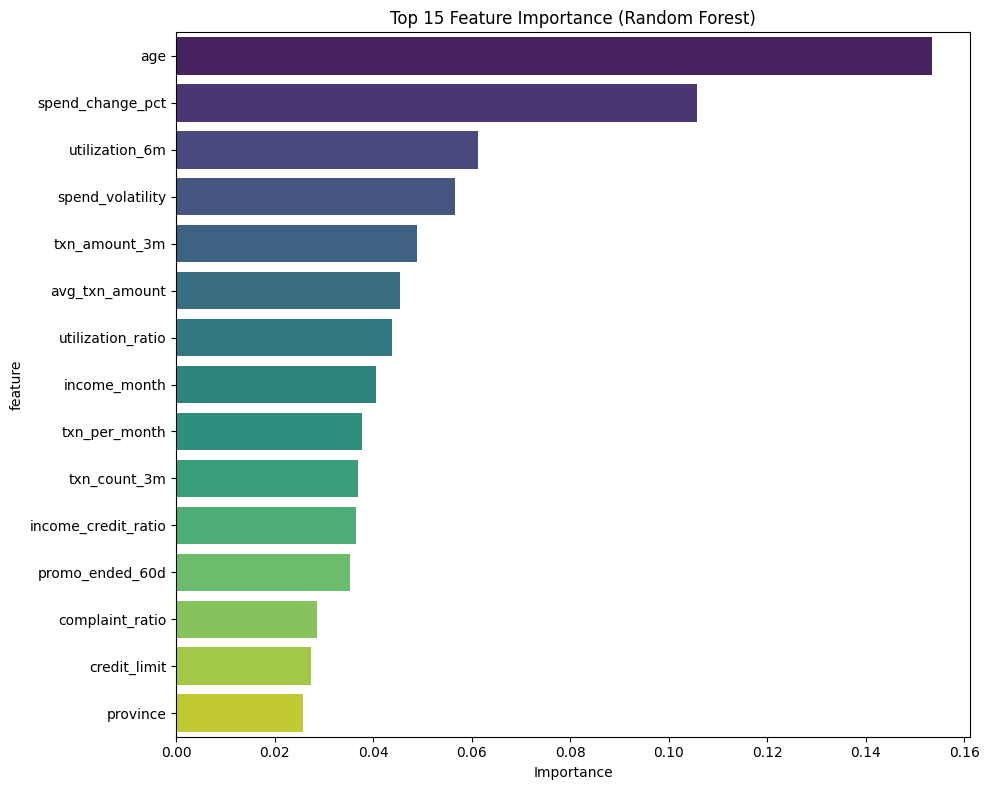

In [26]:
print("BƯỚC 7: FEATURE IMPORTANCE\n")

importances = rf.feature_importances_
feat_imp = pd.DataFrame({
    'feature': all_feature_cols,
    'importance': importances
}).sort_values('importance', ascending=False)

print("Top 15 features quan trọng nhất:")
display(feat_imp.head(15))

# Plot
fig, ax = plt.subplots(figsize=(10, 8))
sns.barplot(data=feat_imp.head(15), x='importance', y='feature', palette='viridis')
ax.set_title('Top 15 Feature Importance (Random Forest)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

In [28]:
print("BƯỚC 8: TẠO SUBMISSION")

# Chọn model tốt nhất
best_model = lgb_model if lgb_auc > max(rf_auc, gb_auc) else (
    gb if gb_auc > rf_auc else rf
)
print(f"Best model: {best_model.__class__.__name__}")

# Nếu có test.csv 
test_path = DATA / "test.csv"
if test_path.exists():
    test = pd.read_csv(test_path)
    
    # Predict
    if isinstance(best_model, lgb.LGBMClassifier):
        test_proba = best_model.predict_proba(test[all_feature_cols].fillna(test[all_feature_cols].median()))[:, 1]
    else:
        test_proba = best_model.predict_proba(test[all_feature_cols].fillna(test[all_feature_cols].median()))[:, 1]
    
    sub = pd.DataFrame({
        'customer_id': test['customer_id'],
        'churn_3m': np.clip(test_proba, 0, 1)
    })
    sub.to_csv('submission.csv', index=False)
    print(f"Submission saved: {len(sub)} rows")
    display(sub.head())
else:
    print("Format submission cần có: customer_id, churn_3m")
    print(f"Sample submission shape: {sample_sub.shape}")
    display(sample_sub.head())

BƯỚC 8: TẠO SUBMISSION
Best model: GradientBoostingClassifier
Format submission cần có: customer_id, churn_3m
Sample submission shape: (8000, 2)


,customer_id,churn_3m
0,CUSJCOH081,0.12
1,CUSFDBKK99,0.12
2,CUS7DPD79Y,0.12
3,CUSDCOU57Y,0.12
4,CUS4NO88FF,0.12
